# Day 7 · 1주차 총정리: 14문항 한 번에
AICE 2주 합격 플랜 · 영상 7편과 함께 풉니다. 공식 샘플 14문항과 같은 순서·형식을 연습 데이터로 처음부터 끝까지 풉니다.
- 시험처럼 위에서부터 차례로 푸세요. 앞 문항의 결과를 뒤 문항이 씁니다.
- 준비 칸에 없는 도구(train_test_split, StandardScaler, GridSearchCV 등)는 시험처럼 답 칸에서 직접 import 하세요.
- 빈칸 문제는 빈칸에 들어갈 말을 `답안N_1` 같은 변수에 **문자열로** 저장합니다.

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 연습 데이터 내려받기
아래 셀을 먼저 실행하세요. 같은 폴더에 `aice_practice.csv` 가 생깁니다.

In [1]:
!wget -q -O aice_practice.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/aice_practice.csv
import os
print('준비 완료' if os.path.exists('aice_practice.csv') and os.path.getsize('aice_practice.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


## 1. [직접 작성] scikit-learn 을 별칭 sk 로 불러오세요

In [2]:
import sklearn as sk

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## 2. [직접 작성] aice_practice.csv 를 읽어 `data` 에 저장하고 첫 4개 행을 출력하세요

In [7]:
data = pd.read_csv('aice_practice.csv')
data.head(4)

,Survived,Pclass,Sex,Age,Fare,Embarked
0,0,3,male,17.0,7.47,C
1,1,2,female,19.0,20.62,S
2,1,3,female,62.0,6.94,C
3,1,3,female,53.0,17.53,C


## 3. [빈칸 채우기] Embarked 개수(countplot)와 Survived 별 Age 분포(histplot)를 가로로 나란히 그리고, 제목을 'Port Count', 'Age by Survived' 로 붙이세요
- 빈칸에 들어갈 말을 `답안3_1`, `답안3_2`, `답안3_3` 에 저장하세요.

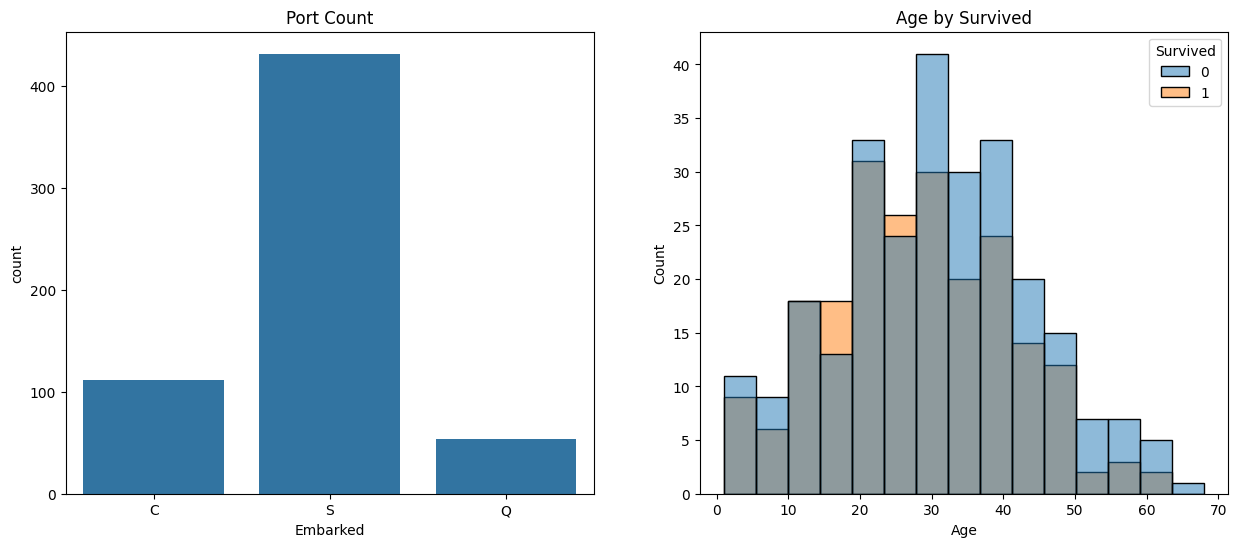

In [9]:
# 아래 코드의 빈칸을 채우고 실행하세요.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
sns.countplot(data=data, x='Embarked', ax=axes[0])
sns.histplot(data=data, x='Age', hue='Survived', ax=axes[1])
axes[0].set_title('Port Count')
axes[1].set_title('Age by Survived')
plt.show()

답안3_1 = 'subplots'
답안3_2 = 'axes'
답안3_3 = 'set_title'

## 4. [직접 작성] x 축에 Pclass, y 축에 Fare 를 두고 boxplot 을 그리세요

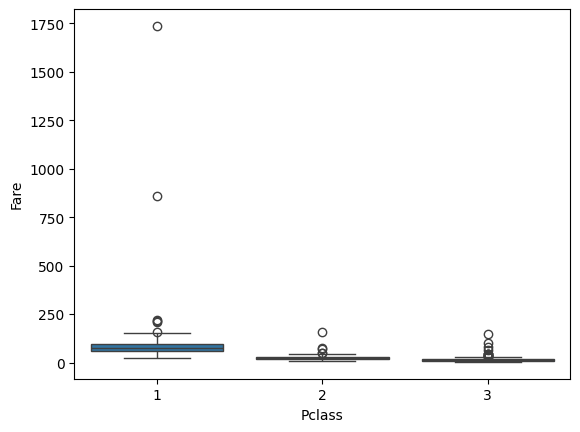

In [10]:
sns.boxplot(data=data, x='Pclass', y='Fare')
plt.show()

## 5. [빈칸 채우기] Fare 가 IQR 울타리 밖인 행을 삭제해 `data_temp` 에 저장하고 인덱스를 초기화하세요
- 빈칸에 들어갈 말을 `답안5_1`, `답안5_2` 에 저장하세요.

In [11]:
# 아래 코드의 빈칸을 채우고 실행하세요.
q1 = data['Fare'].quantile(0.25)
q3 = data['Fare'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
data_temp = data.drop(data[(data['Fare'] > upper_fence) | (data['Fare'] < lower_fence)].index, axis=0)
data_temp.reset_index(drop=True, inplace=True)

답안5_1 = 'drop'
답안5_2 = 'index'

## 6. [빈칸 채우기] 결측치 개수를 확인하고, 결측치가 있는 행을 모두 삭제해 `data_na` 에 저장하세요
- 빈칸에 들어갈 말을 `답안6_1`, `답안6_2` 에 저장하세요.

In [12]:
# 아래 코드의 빈칸을 채우고 실행하세요.
print(data_temp.isnull().sum())
data_na = data_temp.dropna()
print(data_na.isnull().sum())

답안6_1 = 'isnull'
답안6_2 = 'dropna'

Survived      0
Pclass        0
Sex           0
Age         109
Fare          0
Embarked      2
dtype: int64
Survived    0
Pclass      0
Sex         0
Age         0
Fare        0
Embarked    0
dtype: int64


## 7. [빈칸 채우기 + 오류 정정] Embarked 의 C, Q 를 'other' 로 바꾸고, Sex 와 Embarked 를 원 핫 인코딩해 `data_preset` 에 저장하세요
- 빈칸을 채우고, 틀린 함수 이름을 고치세요.
- 바꾼 뒤 'other' 의 개수를 `답안7` 에 저장하세요(이 문항은 빈칸 답을 따로 저장하지 않아요).

In [14]:
# 아래 코드의 빈칸을 채우고 오류를 정정하세요.
data_na = data_na.copy()
data_na.loc[data_na['Embarked'].isin(['C', 'Q']), ['Embarked']] = 'other'
print(data_na['Embarked'].value_counts())
data_preset = pd.get_dummies(data=data_na, columns=['Sex', 'Embarked'])
data_preset.info()

답안7 = (data_na['Embarked']=='other').sum()
답안7

Embarked
S        313
other    124
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 437 entries, 0 to 545
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Survived        437 non-null    int64  
 1   Pclass          437 non-null    int64  
 2   Age             437 non-null    float64
 3   Fare            437 non-null    float64
 4   Sex_female      437 non-null    bool   
 5   Sex_male        437 non-null    bool   
 6   Embarked_S      437 non-null    bool   
 7   Embarked_other  437 non-null    bool   
dtypes: bool(4), float64(2), int64(2)
memory usage: 18.8 KB


np.int64(124)

## 8. [직접 작성] Survived 를 y, 나머지를 X 로 하고 학습용·검증용을 70:30 으로 나누세요
- 변수: `X_train, X_valid, y_train, y_valid` · 시드 7 · 답 비율 유지

In [15]:
from sklearn.model_selection import train_test_split
X = data_preset.drop('Survived', axis=1)
y = data_preset['Survived']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)

## 9. [오류 정정] 스케일링 코드를 고치고, 검증 데이터 최댓값을 반올림해 `답안9` 에 저장하세요
- 에러 없이 결과만 틀립니다.
- 이 셀은 X_train, X_valid 를 덮어씁니다. 고친 뒤 다시 실행할 때는 8번 셀부터 다시 실행하세요.

In [16]:
# 아래의 코드를 정정하고 실행하세요.
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
답안9 = round(np.max(X_valid))
답안9

3

## 10. [직접 작성] DecisionTree(`gs_dt`)와 RandomForest(`gs_rf`)를 GridSearchCV 로 학습하세요
- DT: max_depth [3, 5, 7, 10], min_samples_split [2, 3, 5, 10] · RF: n_estimators [100, 200, 500], max_depth [5, 10, 20], min_samples_split [2, 5, 10]
- cv=3, scoring='accuracy', n_jobs=-1, 난수 시드 7 · RF 최적 분류기 개수를 `답안10` 에 저장하세요.

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

gs_dt = GridSearchCV(estimator=DecisionTreeClassifier(random_state=7), param_grid={'max_depth':[3,5,7,10], 'min_samples_split':[2,3,5,10]}, cv=3, scoring='accuracy', n_jobs=-1)
gs_dt.fit(X_train, y_train)

gs_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=7), param_grid={'n_estimators':[100,200,500], 'max_depth':[5,10,20], 'min_samples_split':[2,5,10]}, cv=3, scoring='accuracy', n_jobs=-1)
gs_rf.fit(X_train, y_train)

print(gs_rf.best_estimator_)

답안10 = gs_rf.best_params_['n_estimators']
답안10

RandomForestClassifier(max_depth=5, n_estimators=500, random_state=7)


500

## 11. [오류 정정] 변수 중요도 top 10 을 그리고, 1위 컬럼 이름을 `답안11` 에 저장하세요

'Fare'

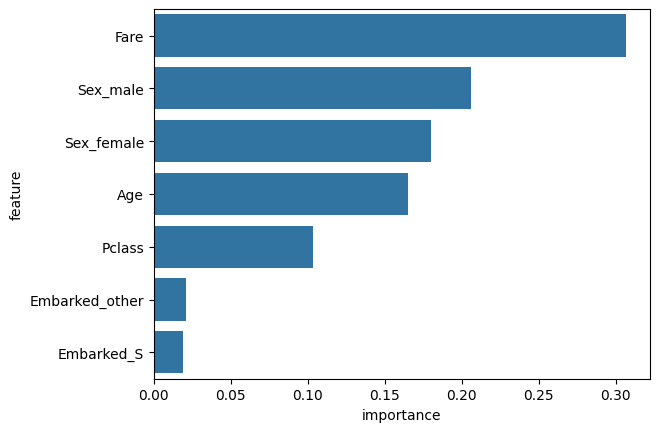

In [20]:
# 아래의 코드를 정정하고 실행하세요.
fi = pd.DataFrame({'feature': X.columns, 'importance': gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)

답안11 = fi.iloc[0]['feature']
답안11

## 12. [오류 정정] 두 모델의 검증 정확도를 구하고, 더 좋은 모델 이름을 `답안12` 에 저장하세요 ('DecisionTree' 또는 'RandomForest')

In [22]:
# 아래의 코드를 정정하고 실행하세요.
from sklearn.metrics import accuracy_score
dt_acc = accuracy_score(y_valid, gs_dt.predict(X_valid))
rf_acc = accuracy_score(y_valid, gs_rf.predict(X_valid))
print(dt_acc, rf_acc)

답안12 = 'RandomForest' if rf_acc > dt_acc else 'DecisionTree'
답안12

0.696969696969697 0.6893939393939394


'DecisionTree'

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
tf.keras.utils.set_random_seed(1)

## 13. [빈칸 채우기] 딥러닝 모델을 만들고 학습하세요 (Dense 64 relu → Dropout 0.3 → Dense 32 relu → Dense 2 sigmoid)
- 정답은 LabelEncoder → to_categorical · val_loss 가 10번 나아지지 않으면 멈춤 · 30바퀴, 배치 64 · 학습 정보는 `history`
- 빈칸에 들어갈 말을 `답안13_1`, `답안13_2` 에 저장하세요.

In [24]:
# 아래 코드의 빈칸을 채우고 실행하세요.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_c = to_categorical(le.fit_transform(y_train))
y_valid_c = to_categorical(le.transform(y_valid))
model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid')
])
estop = EarlyStopping(monitor='val_loss', patience=10)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train_c, epochs=30, batch_size=64, validation_data=(X_valid, y_valid_c), callbacks=[estop])

답안13_1 = 'Dropout'
답안13_2 = 'patience'

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.5082 - loss: 0.7259 - val_accuracy: 0.5455 - val_loss: 0.6994
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5541 - loss: 0.6852 - val_accuracy: 0.5833 - val_loss: 0.6730
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6164 - loss: 0.6614 - val_accuracy: 0.6515 - val_loss: 0.6508
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7049 - loss: 0.6222 - val_accuracy: 0.6818 - val_loss: 0.6322
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6918 - loss: 0.6174 - val_accuracy: 0.6970 - val_loss: 0.6165
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7410 - loss: 0.5822 - val_accuracy: 0.6970 - val_loss: 0.6038
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7311 - loss: 0.5799 - val_accuracy: 0.7045 - val_loss: 0.5936
Epoch 8/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7344 - loss: 0.5732 - val_accuracy: 0.6970 - val_loss: 0.5860


## 14. [직접 작성] 학습 Accuracy 와 검증 Accuracy 를 한 그래프에 그리세요
- 범례 'acc', 'val_acc' · 제목 'Model Accuracy' · x축 'Epoch' · y축 'Accuracy'

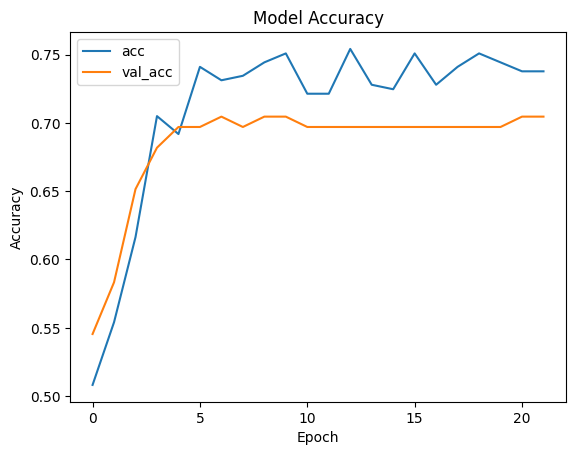

In [27]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['acc', 'val_acc'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

---
### 자주 하는 실수 10 (영상 7편)
1. shape() → shape
2. 조건마다 괄호
3. mode() → mode()[0]
4. drop(df[조건]) → drop(df[조건].index)
5. 컬럼 삭제는 axis=1
6. 검증용은 transform
7. accuracy → accuracy_score
8. pred → predict (best_estimator_)
9. sort_index → sort_values
10. 마지막 층 칸 수 = 정답 자리 수